# <center> P value calibration after DEA

 ## <center>Description

- env: seurat_v02

 ## <center> Set-up

 #### **Load libraries**

In [ ]:
# Load libraries
suppressPackageStartupMessages({
    library(dplyr)
    library(fdrtool) # pvalue calibration
    library(readr)
    # plots
    library(ggplot2)
    library(ggsci)
})

 #### **Paths**

In [ ]:

dir_script='/gpfs/bwfor/home/hd/hd_hd/hd_gb249/sds-hd/sd22b002/projects/olabisi/workflow/scripts/DEA/'

# input
in_deg=paste0(dir_script, '../../../output/DEA/objects/pyDESeq2/deg.tsv')

# output
## objects
out_objects_folder=file.path(dir_script, '../../../output/DEA/objects/calibrate_pvalues')
if (!dir.exists(out_objects_folder)) { dir.create(out_objects_folder,recursive=TRUE,showWarnings = FALSE) }
out_deg=file.path(out_objects_folder, 'deg_calibrated.tsv')
## plots
out_plots=file.path(dir_script, '../../../output/DEA/plots/calibrate_pvalues')
if (!dir.exists(out_plots)) { dir.create(out_plots,recursive=TRUE,showWarnings = FALSE) }


 ## <center>Main

#### **Load degs**

In [ ]:
deg = readr::read_delim(file=in_deg, delim='\t', show_col_types=FALSE) #%>%
    #tibble::column_to_rownames(var = names(.)[1])

head(deg)

gene_id,genesymbol,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,contrast,significant_pvalue_0.05,significant_padj_0.05,direction
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<lgl>,<lgl>,<chr>
ENSG00000283293,RN7SK,455.74788,-4.375801,0.5532971,-7.908591,2.603179e-15,5.090777e-11,HR_case__IFNG_pos_vs_HR_control__IFNG_pos,TRUE,TRUE,higher_HR_control__IFNG_pos
ENSG00000202198,7SK,303.68863,-3.769521,0.5277419,-7.142735,9.149167e-13,8.946056e-09,HR_case__IFNG_pos_vs_HR_control__IFNG_pos,TRUE,TRUE,higher_HR_control__IFNG_pos
ENSG00000202058,RN7SKP80,14.95115,-5.132970,0.8581451,-5.981471,2.211309e-09,1.441479e-05,HR_case__IFNG_pos_vs_HR_control__IFNG_pos,TRUE,TRUE,higher_HR_control__IFNG_pos
ENSG00000269900,nan,43.45088,-2.420166,0.4485158,-5.395944,6.816422e-08,3.332549e-04,HR_case__IFNG_pos_vs_HR_control__IFNG_pos,TRUE,TRUE,higher_HR_control__IFNG_pos
ENSG00000081237,PTPRC,27.42866,-5.929187,1.1213672,-5.287462,1.240248e-07,4.773074e-04,HR_case__IFNG_pos_vs_HR_control__IFNG_pos,TRUE,TRUE,higher_HR_control__IFNG_pos
ENSG00000277209,RPPH1,80.46913,-2.079612,0.3955908,-5.256976,1.464432e-07,4.773074e-04,HR_case__IFNG_pos_vs_HR_control__IFNG_pos,TRUE,TRUE,higher_HR_control__IFNG_pos


#### **calibrate**

In [ ]:
# function from Charlotte Boys for P value calibration using fdrtool package

calibrate <- function(res, plot = F){
  # Remove any outliers - genes with NA pvals
  res_corrected <- res[!is.na(res$pvalue), ]
  # Use z-scores as input to FDRtool to re-estimate the p-values
  recalibrated_pvals <- fdrtool::fdrtool(res_corrected$stat, statistic='normal', plot = plot)
  # Report the null model variance
  print("Standard deviation of the null model: ")
  print(recalibrated_pvals$param[1, "sd"])
  # Add re-calibrated p-values and their BH-adjusted values to the results
  res_corrected$pvalue <- recalibrated_pvals$pval
  res_corrected$padj <- p.adjust(recalibrated_pvals$pval, method = "BH")
  return(res_corrected)
}

Step 1... determine cutoff point
Step 2... estimate parameters of null distribution and eta0
Step 3... compute p-values and estimate empirical PDF/CDF
Step 4... compute q-values and local fdr
Step 5... prepare for plotting



[1] "Standard deviation of the null model: "
      sd 
0.820809 


gene_id,genesymbol,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,contrast,significant_pvalue_0.05,significant_padj_0.05,direction
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<lgl>,<lgl>,<chr>
ENSG00000283293,RN7SK,455.74788,-4.375801,0.5532971,-7.908591,2.220446e-16,2.171152e-12,HR_case__IFNG_pos_vs_HR_control__IFNG_pos,TRUE,TRUE,higher_HR_control__IFNG_pos
ENSG00000202198,7SK,303.68863,-3.769521,0.5277419,-7.142735,2.220446e-16,2.171152e-12,HR_case__IFNG_pos_vs_HR_control__IFNG_pos,TRUE,TRUE,higher_HR_control__IFNG_pos
ENSG00000202058,RN7SKP80,14.95115,-5.132970,0.8581451,-5.981471,3.161915e-13,2.061147e-09,HR_case__IFNG_pos_vs_HR_control__IFNG_pos,TRUE,TRUE,higher_HR_control__IFNG_pos
ENSG00000269900,nan,43.45088,-2.420166,0.4485158,-5.395944,4.900302e-11,2.395758e-07,HR_case__IFNG_pos_vs_HR_control__IFNG_pos,TRUE,TRUE,higher_HR_control__IFNG_pos
ENSG00000081237,PTPRC,27.42866,-5.929187,1.1213672,-5.287462,1.180884e-10,4.618675e-07,HR_case__IFNG_pos_vs_HR_control__IFNG_pos,TRUE,TRUE,higher_HR_control__IFNG_pos
ENSG00000277209,RPPH1,80.46913,-2.079612,0.3955908,-5.256976,1.507365e-10,4.913006e-07,HR_case__IFNG_pos_vs_HR_control__IFNG_pos,TRUE,TRUE,higher_HR_control__IFNG_pos


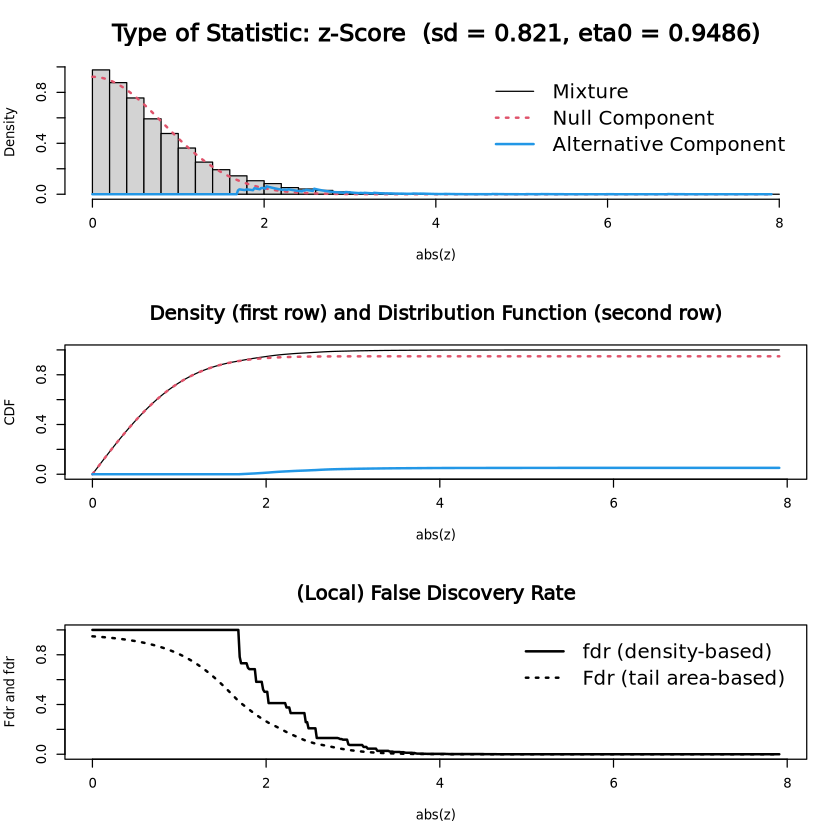

In [ ]:
# do the calibration

df_degs = calibrate(deg,plot=T)

head(df_degs)

In [ ]:
# how many degs?
ndegs=sum(df_degs$padj < 0.05)
print(paste0('Number of DEGs: ',ndegs,' (',round(ndegs/nrow(df_degs)*100,2),' %)'))

[1] "Number of DEGs: 211 (1.08 %)"


## <center> Save results

In [ ]:
# degs
df_degs %>% write.table(., file=out_deg, quote=FALSE, sep='\t', col.names = NA)

## <center> Plot results

In [ ]:
theme_set( theme_classic() + theme(plot.title = element_text(size=12, hjust=0.5, face="bold"), 
                                   axis.title = element_text(size=11),
                                   axis.text = element_text(size=10),
                                   axis.line = element_line(linewidth=0.6),
                                   axis.ticks = element_line(linewidth=1.5),
                                   panel.grid = element_line(linewidth=1), 
                                   panel.grid.minor = element_blank()))

#### **Pvalue histogram**

In [ ]:
p=ggplot(df_degs, aes(x=pvalue)) +
    geom_histogram(breaks = seq(0, 1, 0.05),color = "black", fill = "grey") +
    labs(title='Pvalue histogram', subtitle = paste0('(calibrated P values)'))

p %>% ggsave(filename=file.path(out_plots, "P_hist.png"))

Saving 6.67 x 6.67 in image


#### **n DEGs**

In [ ]:
# P
plotTab = df_degs %>%
dplyr::mutate(pass_p=pvalue<0.05) %>%
group_by(contrast, pass_p) %>%
summarise(n = dplyr::n()) %>% ungroup() %>%
dplyr::mutate(pass_p=factor(pass_p, levels=c(TRUE, FALSE)))

p=ggplot(plotTab, aes(x=pass_p, y=n)) +
    geom_col(color = "black", fill = "grey") +
    geom_text(aes(label=n, vjust=-1)) +
    labs(title='Pass pvalue') +
    facet_wrap(~contrast)

p %>% ggsave(filename=file.path(out_plots, 'n_pass_P.png'))

`summarise()` has grouped output by 'contrast'. You can override using the
`.groups` argument.
Saving 6.67 x 6.67 in image


In [ ]:
# padj
plotTab = df_degs %>%
dplyr::mutate(pass_p=padj<0.05) %>%
group_by(contrast, pass_p) %>%
summarise(n = dplyr::n()) %>% ungroup() %>%
dplyr::mutate(pass_p=factor(pass_p, levels=c(TRUE, FALSE)))

p=ggplot(plotTab, aes(x=pass_p, y=n)) +
    geom_col(color = "black", fill = "grey") +
    geom_text(aes(label=n, vjust=-1.2)) +
    labs(title='Pass padj') +
    facet_wrap(~contrast)

p %>% ggsave(filename=file.path(out_plots, 'n_pass_padj.png'))

`summarise()` has grouped output by 'contrast'. You can override using the
`.groups` argument.


Saving 6.67 x 6.67 in image
